In [49]:
# IMPORT LIBRARIES

In [50]:
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch 
import torch.nn as nn 
import nltk
import torch.optim as optim
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from torchtext.data import get_tokenizer
import seaborn as sns
from sklearn.metrics import accuracy_score

from sklearn.model_selection import train_test_split
import re

In [51]:
# CONFIG 
TRUE_DATA_PATH = 'data/True.csv'
FALSE_DATA_PATH = 'data/Fake.csv'

import torchtext.data as data
data.Field()

# LOAD DATA 

In [52]:
true_df = pd.read_csv(TRUE_DATA_PATH)
false_df = pd.read_csv(FALSE_DATA_PATH)

In [53]:
true_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [54]:
false_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [55]:
true_df['category'] = np.ones(len(true_df), dtype=int)
false_df['category'] = np.zeros(len(false_df), dtype=int)

true_df.head()

,title,text,subject,date,category
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


<BarContainer object of 1 artists>

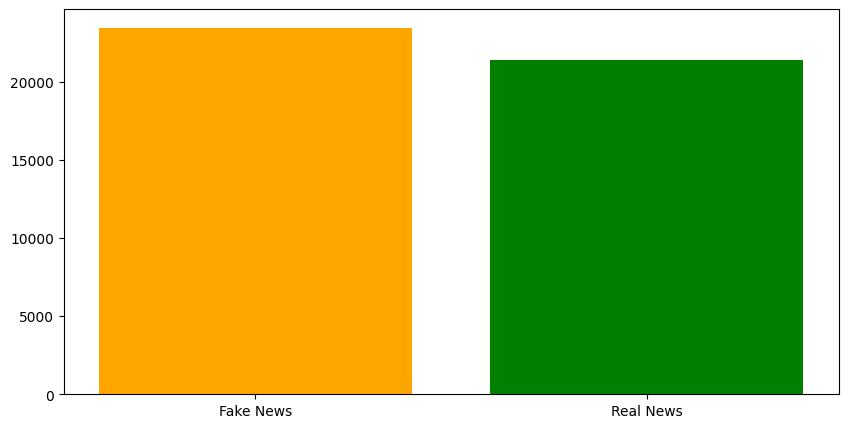

In [56]:
plt.figure(figsize=(10, 5))
plt.bar('Fake News', len(false_df), color='orange')
plt.bar('Real News', len(true_df), color='green')

In [57]:
# Difference of the Fake and Real News
print(f'Difference between Fake and Real News: {len(false_df) - len(true_df)}')

Difference between Fake and Real News: 2064


In [58]:
# concat = merging datasets
news_df = pd.concat([true_df, false_df], axis=0)
news_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44898 entries, 0 to 23480
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     44898 non-null  object
 1   text      44898 non-null  object
 2   subject   44898 non-null  object
 3   date      44898 non-null  object
 4   category  44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 2.1+ MB


In [59]:
news_df = news_df.sample(frac=1)
news_df.head(5)

,title,text,subject,date,category
1718,American Airlines Crew Hits Woman With Stroll...,Yet another example of our airline industry s ...,News,"April 22, 2017",0
8654,Alaska's top court rejects parental notice for...,SEATTLE (Reuters) - An Alaska law requiring do...,politicsNews,"July 23, 2016",1
2860,"Trump backtracks on U.S.-Russia cyber unit, sa...",WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"July 10, 2017",1
20621,THIS 21 YEAR OLD TEXAN WOMAN GETS IT: “Put Me ...,Wow! This 21 year old Texan woman recently pen...,left-news,"May 5, 2016",0
1134,"Trump Accuses Qatar Of Funding Terrorism, Sel...",It was only last week that Donald Trump was ca...,News,"June 15, 2017",0


In [60]:
news_df['subject'].value_counts()

subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64

In [61]:
news_df = pd.get_dummies(news_df, columns=['subject'])
news_df.head()

,title,text,date,category,subject_Government News,subject_Middle-east,subject_News,subject_US_News,subject_left-news,subject_politics,subject_politicsNews,subject_worldnews
1718,American Airlines Crew Hits Woman With Stroll...,Yet another example of our airline industry s ...,"April 22, 2017",0,False,False,True,False,False,False,False,False
8654,Alaska's top court rejects parental notice for...,SEATTLE (Reuters) - An Alaska law requiring do...,"July 23, 2016",1,False,False,False,False,False,False,True,False
2860,"Trump backtracks on U.S.-Russia cyber unit, sa...",WASHINGTON (Reuters) - U.S. President Donald T...,"July 10, 2017",1,False,False,False,False,False,False,True,False
20621,THIS 21 YEAR OLD TEXAN WOMAN GETS IT: “Put Me ...,Wow! This 21 year old Texan woman recently pen...,"May 5, 2016",0,False,False,False,False,True,False,False,False
1134,"Trump Accuses Qatar Of Funding Terrorism, Sel...",It was only last week that Donald Trump was ca...,"June 15, 2017",0,False,False,True,False,False,False,False,False


In [62]:
news_df = news_df.drop('date', axis=1)
news_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44898 entries, 1718 to 15811
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   title                    44898 non-null  object
 1   text                     44898 non-null  object
 2   category                 44898 non-null  int64 
 3   subject_Government News  44898 non-null  bool  
 4   subject_Middle-east      44898 non-null  bool  
 5   subject_News             44898 non-null  bool  
 6   subject_US_News          44898 non-null  bool  
 7   subject_left-news        44898 non-null  bool  
 8   subject_politics         44898 non-null  bool  
 9   subject_politicsNews     44898 non-null  bool  
 10  subject_worldnews        44898 non-null  bool  
dtypes: bool(8), int64(1), object(2)
memory usage: 1.7+ MB


In [88]:
new_text = []
pattern = "[^a-zA-Z]"
nltk.download()
lemma = nltk.WordNetLemmatizer()

for txt in tqdm(news_df.text):
    
    txt = re.sub(pattern," ",txt) # Cleaning
    txt = txt.lower() # Lowering
    txt = nltk.word_tokenize(txt) # Tokenizing
    txt = [lemma.lemmatize(word) for word in txt] # Lemmatizing
    txt = " ".join(txt)
    new_text.append(txt)
    
    
new_text[0]

showing info https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/index.xml


In [64]:
new_title = []
for txt in tqdm(news_df.title):
    
    txt = re.sub(pattern," ",txt) # Cleaning
    txt = txt.lower() # Lowering
    txt = nltk.word_tokenize(txt) # Tokenizing
    txt = [lemma.lemmatize(word) for word in txt] # Lemmatizing
    txt = " ".join(txt)
    new_title.append(txt)
new_title[0]

'american airline crew hit woman with stroller challenge passenger to fight video'

In [65]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer_title = CountVectorizer(stop_words="english",max_features=1000)
vectorizer_text = CountVectorizer(stop_words="english",max_features=4000)

title_matrix = vectorizer_title.fit_transform(new_title).toarray() 
text_matrix = vectorizer_text.fit_transform(new_text).toarray()

print("Finished")

Finished


In [66]:
news_df.head(5)

,title,text,category,subject_Government News,subject_Middle-east,subject_News,subject_US_News,subject_left-news,subject_politics,subject_politicsNews,subject_worldnews
1718,American Airlines Crew Hits Woman With Stroll...,Yet another example of our airline industry s ...,0,False,False,True,False,False,False,False,False
8654,Alaska's top court rejects parental notice for...,SEATTLE (Reuters) - An Alaska law requiring do...,1,False,False,False,False,False,False,True,False
2860,"Trump backtracks on U.S.-Russia cyber unit, sa...",WASHINGTON (Reuters) - U.S. President Donald T...,1,False,False,False,False,False,False,True,False
20621,THIS 21 YEAR OLD TEXAN WOMAN GETS IT: “Put Me ...,Wow! This 21 year old Texan woman recently pen...,0,False,False,False,False,True,False,False,False
1134,"Trump Accuses Qatar Of Funding Terrorism, Sel...",It was only last week that Donald Trump was ca...,0,False,False,True,False,False,False,False,False


In [67]:
news_df.drop(['title', 'text'], axis=1, inplace=True)
news_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44898 entries, 1718 to 15811
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   category                 44898 non-null  int64
 1   subject_Government News  44898 non-null  bool 
 2   subject_Middle-east      44898 non-null  bool 
 3   subject_News             44898 non-null  bool 
 4   subject_US_News          44898 non-null  bool 
 5   subject_left-news        44898 non-null  bool 
 6   subject_politics         44898 non-null  bool 
 7   subject_politicsNews     44898 non-null  bool 
 8   subject_worldnews        44898 non-null  bool 
dtypes: bool(8), int64(1)
memory usage: 1.0 MB


In [68]:
print(news_df.shape)
print(title_matrix.shape)
print(text_matrix.shape)

(44898, 9)
(44898, 1000)
(44898, 4000)


In [69]:
X = np.concatenate((np.array(news_df.drop('category', axis=1)), title_matrix,
                     text_matrix), axis=1)

y = news_df.category

In [70]:
print(X.shape)
print(y.shape)

(44898, 5008)
(44898,)


In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, np.array(y), 
                                                    test_size=0.25, 
                                                    random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(33673, 5008)
(11225, 5008)
(33673,)
(11225,)


In [72]:
## BUILDING MODEL

In [77]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NewsClassifier(nn.Module):
    def __init__(self):
        super(NewsClassifier, self).__init__()
        
        # Fully connected layers
        self.linear1 = nn.Linear(5008, 2000)
        self.relu1 = nn.ReLU()
        self.linear2 = nn.Linear(2000, 500)
        self.relu2 = nn.ReLU()
        self.linear3 = nn.Linear(500, 100)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.1)
        self.linear4 = nn.Linear(100, 20)
        self.relu4 = nn.ReLU()
        self.linear5 = nn.Linear(20, 2)

    def forward(self, x):
        # Fully connected layers
        out = self.linear1(x)
        out = self.relu1(out)
        out = self.linear2(out)
        out = self.relu2(out)
        out = self.linear3(out)
        out = self.relu3(out)
        out = self.dropout(out)
        out = self.linear4(out)
        out = self.relu4(out)
        out = self.linear5(out)

        return out


In [78]:
model = NewsClassifier()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

In [86]:
import torch
from tqdm import tqdm

X_train = torch.Tensor(X_train)
y_train = torch.Tensor(y_train).type(torch.LongTensor)

X_test = torch.Tensor(X_test)
y_test = torch.Tensor(y_test).type(torch.LongTensor)

EPOCHS = 20

for epoch in tqdm(range(EPOCHS)):
    optimizer.zero_grad()

    # Forward pass
    outputs = model(X_train)
    
    # Calculate loss
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    # Calculate accuracy
    _, predicted = torch.max(outputs, 1)
    correct = (predicted == y_train).sum().item()
    accuracy = correct / len(y_train) * 100.0

    print(f'Epoch [{epoch+1}/{EPOCHS}], Loss: {loss.item():.4f}, Accuracy: {accuracy:.2f}%')

Epoch [1/20], Loss: 0.0024, Accuracy: 99.95%


Epoch [2/20], Loss: 0.0032, Accuracy: 99.91%


Epoch [3/20], Loss: 0.0020, Accuracy: 99.97%


Epoch [4/20], Loss: 0.0009, Accuracy: 99.98%


Epoch [5/20], Loss: 0.0008, Accuracy: 99.98%


Epoch [6/20], Loss: 0.0008, Accuracy: 99.98%


... (10 outputs left out)

Epoch [17/20], Loss: 0.0000, Accuracy: 100.00%


Epoch [18/20], Loss: 0.0000, Accuracy: 100.00%


Epoch [19/20], Loss: 0.0000, Accuracy: 100.00%


Epoch [20/20], Loss: 0.0000, Accuracy: 100.00%


# Evaluating


In [87]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test)
    _, predicted = torch.max(test_outputs, 1)
    correct = (predicted == y_test).sum().item()
    test_accuracy = correct / len(y_test) * 100.0
    test_loss = criterion(test_outputs, y_test)

print(f'Test Accuracy: {test_accuracy:.2f}%')
print(f'Test Loss: {test_loss:.2f}%')


Test Accuracy: 99.44%
Test Loss: 0.05%
